# Run 2: leak-free split, YOLOv8n vs YOLOv8s, cost-based threshold

What changes from run 1, and why (evidence from run 1):

| Change | Why |
|---|---|
| Whole video **segments** go to train / valid / test | Run 1: 80/80 test trays had a training frame within ±30 frames |
| **YOLOv8n vs YOLOv8s**, the better one chosen on *validation* | Accuracy is the bottleneck; speed has ~11x headroom |
| Threshold chosen by **cost of mistakes** on validation | Run 1 rejected 5 of 12 good trays |
| CNN trained 50 epochs | Run 1 validation F1 was still rising at epoch 25 |
| "Always FAIL" baseline + paired bootstrap built in | Needed to judge whether a model learned anything |

**Local (RTX GPU, VS Code):** open this notebook from the repo's `notebooks/` folder; results are written straight into `results/run2/`. **Colab:** Runtime → Change runtime type → **T4 GPU**. **Kaggle:** Settings → Accelerator → **GPU T4 x2** (or P100) and Internet **on**. Close other heavy apps (browser tabs, games) before a local run: training needs several GB of RAM. Then run the cells **one at a time** down to cell 4 and set `GAP` from what it prints. Then Runtime → Run after. About 2 hours.

In [8]:
# 1. SETUP
# Works in three places: Colab, Kaggle, or locally (VS Code, opened from the repo's notebooks/ folder).
GITHUB_USER, REPO = "anhtruong27", "pork-rasher-inspection"
import os, sys, shutil
from pathlib import Path
here = Path.cwd()
if (here / "src" / "porkinspect").exists():                 # already at the repo root (local)
    pass
elif (here.parent / "src" / "porkinspect").exists():        # opened from notebooks/ (local)
    os.chdir(here.parent)
else:                                                        # Colab / Kaggle: get the code from GitHub
    if not os.path.exists(REPO):
        !git clone https://github.com/{GITHUB_USER}/{REPO}.git
    os.chdir(REPO)
    !git pull -q
%pip install -q ultralytics roboflow
print("Working in", os.getcwd())
sys.path.insert(0, "src")
import torch, psutil
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to T4 GPU (Colab) or Accelerator GPU (Kaggle)!")
ram = psutil.virtual_memory()
print(f"RAM: {ram.available / 1e9:.1f} GB free of {ram.total / 1e9:.1f} GB" + ("  <- close other apps before training" if ram.available < 6e9 else ""))

Note: you may need to restart the kernel to use updated packages.
Working in c:\Users\truon\Documents\DU HỌC\Sem 2 - 2026\MMA3001\Project\pork-rasher-inspection
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
RAM: 7.2 GB free of 16.5 GB


In [9]:
# 2. SETTINGS FOR RUN 2  (your decisions: write the reason next to each one)
GAP = 30              # Task 1: no natural break in the frame-gap histogram; largest gap that still leaves 49 segments; >30 frames ~ 1 s if 30 fps
TEST_FRAC = 0.15      # share of original photos held out for test
VALID_FRAC = 0.10     # share for validation
YOLO_MODELS = ["yolov8n.pt", "yolov8s.pt"]   # Task 2: candidates, best picked on VALIDATION
IMGSZ = 640           # Task 2: input size (480 or 640), justify from the run-1 resolution study
EPOCHS = 40
BATCH = 16            # lower to 8 if you get "CUDA out of memory" (6 GB laptop GPU + yolov8s)
WORKERS = 2           # image-loading processes; Ultralytics' default (8) ran out of RAM on a Windows laptop
CNN_EPOCHS = 50
MISS_COST = 10        # Task 3: cost of passing a defective tray ...
WASTE_COST = 1        # ... relative to rejecting a good tray
OUT = "results/run2"
DATA_DIR = "data"     # local Windows: use a short path with only English letters, e.g. "C:/mma_data"
os.makedirs(OUT, exist_ok=True)

In [10]:
# 3. DOWNLOAD DATASET (paste the Roboflow key when asked; it is not saved)
from getpass import getpass
from roboflow import Roboflow
from pathlib import Path
import yaml, json, time
import numpy as np, matplotlib.pyplot as plt
rf = Roboflow(api_key=getpass("Roboflow API key: "))
rf.workspace("hello-2aqe0").project("pork-rasher-error-packaging").version(4).download("yolov8", location=f"{DATA_DIR}/pork", overwrite=True)
DATA = Path(f"{DATA_DIR}/pork").resolve()
cfg = yaml.safe_load((DATA / "data.yaml").read_text())
CLASS_NAMES = list(cfg["names"]) if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]
N = len(CLASS_NAMES)
from porkinspect.data import audit_dataset
_, orig = audit_dataset(DATA, CLASS_NAMES)
ALL = [r for s in ("train", "valid", "test") for r in orig.get(s, [])]
print(len(ALL), "images,", CLASS_NAMES)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to data/pork in yolov8:: 100%|██████████| 7103/7103 [00:03<00:00, 1836.45it/s]


3549 images, ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


1272 original photos, 1271 gaps between neighbouring frames
gap percentiles (50/75/90/95/99%): [          5          11          19        26.5        48.3]
G=   2:   898 segments, largest    6 photos, median 1
G=   5:   606 segments, largest   19 photos, median 1
G=  10:   335 segments, largest   83 photos, median 2
G=  30:    49 segments, largest  479 photos, median 6
G= 100:     1 segments, largest 1272 photos, median 1272
G= 300:     1 segments, largest 1272 photos, median 1272


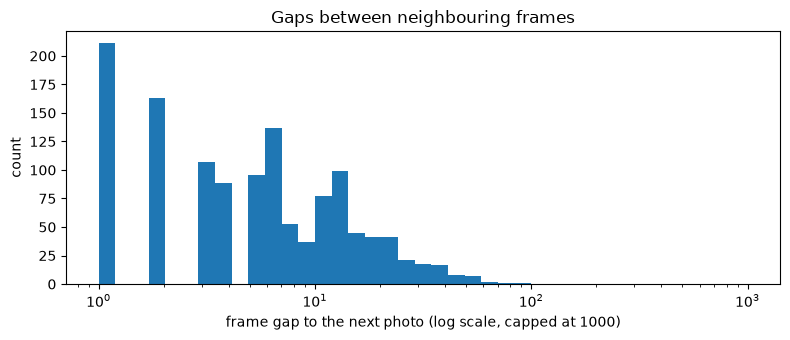

In [11]:
# 4. EVIDENCE FOR CHOOSING GAP (Task 1): how far apart are neighbouring frames?
from porkinspect.data import frame_gaps, assign_segments, unique_sources
g = frame_gaps(ALL)
print(f"{len(unique_sources(ALL))} original photos, {len(g)} gaps between neighbouring frames")
print("gap percentiles (50/75/90/95/99%):", np.percentile(g, [50, 75, 90, 95, 99]).round(1))
for G in (2, 5, 10, 30, 100, 300):
    segs = assign_segments(ALL, G)
    sizes = np.bincount(np.unique(list(segs.values()), return_inverse=True)[1])
    print(f"G={G:4d}: {len(set(segs.values())):5d} segments, largest {sizes.max():4d} photos, median {int(np.median(sizes))}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.clip(g, 1, 1000), bins=np.logspace(0, 3, 40)); ax.set_xscale("log")
ax.set(xlabel="frame gap to the next photo (log scale, capped at 1000)", ylabel="count", title="Gaps between neighbouring frames")
plt.tight_layout(); plt.savefig(f"{OUT}/frame_gaps.png", dpi=150); plt.show()

**Choose `GAP` now** (go back to cell 2, set it, re-run cell 2). Look for where the histogram changes from "frames of one shot" (small gaps) to "breaks between shots" (large gaps). Too small: neighbouring frames of one shot land in different splits (leakage). Too big: only a few huge segments, and the test set may be one single shot. Cell 5b then shows test photos next to their nearest training photo, so you can check by eye that they are different trays.

In [12]:
# 5. BUILD THE LEAK-FREE SPLIT
assert GAP is not None, "Set GAP in cell 2 first"
from porkinspect.data import segment_split, write_yolo_split, near_duplicate_leaks
main = [CLASS_NAMES.index(c) for c in ("packaging-error", "unsealed")]
split = segment_split(ALL, gap=GAP, test_frac=TEST_FRAC, valid_frac=VALID_FRAC, n_classes=N,
                      must_have=main, min_pass=5, seed=0)
DATA2 = write_yolo_split(split, f"{DATA_DIR}/pork_run2", CLASS_NAMES)
report2, records = audit_dataset(DATA2.parent, CLASS_NAMES)
txt = report2.to_text() + f"\n\nGAP = {GAP}, split seed = {split['seed']}\n"
for w in (0, 2, 10, 30, GAP):
    txt += f"test trays with a train/valid frame within {w:4d} frames: {len(near_duplicate_leaks(records['train'] + records['valid'], records['test'], window=w))}\n"
print(txt); Path(f"{OUT}/dataset_audit_run2.txt").write_text(txt)

DATASET AUDIT
train:  2645 images,  520 with no defect boxes
valid:   145 images,   39 with no defect boxes
 test:   195 images,   29 with no defect boxes

class                        train           valid            test   (boxes / images containing class)
loose-meat               57 / 56           2 / 2            3 / 3    
packaging-error        1333 / 1196        55 / 47         100 / 87   
twisted-meat             51 / 51           6 / 5            4 / 4    
unsealed                891 / 891         50 / 50          76 / 76   
wrinkle                  12 / 12           2 / 2            0 / 0    

Malformed label files: 0
Original photos appearing in more than one split (leakage): 0

GAP = 30, split seed = 0
test trays with a train/valid frame within    0 frames: 0
test trays with a train/valid frame within    2 frames: 0
test trays with a train/valid frame within   10 frames: 0
test trays with a train/valid frame within   30 frames: 0
test trays with a train/valid frame within   

1027

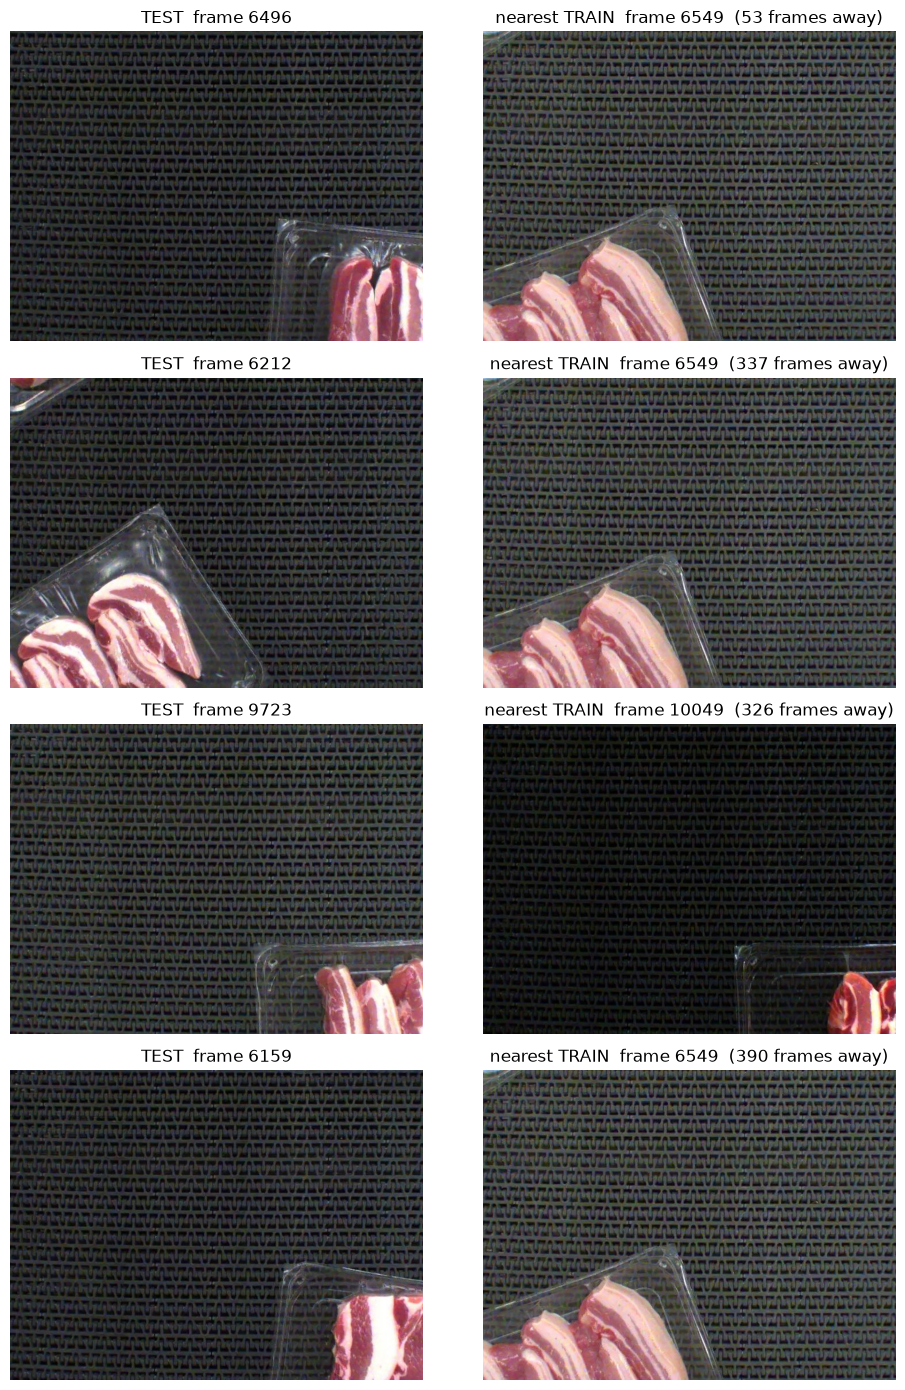

In [13]:
# 5b. EYEBALL CHECK: is the nearest training photo really a DIFFERENT tray?
from porkinspect.data import frame_key
from porkinspect.io_utils import load_image
train_frames = [(frame_key(r.source_id), r) for r in records["train"]]
fig, axes = plt.subplots(4, 2, figsize=(10, 14))
rng = np.random.default_rng(1)
for row, i in zip(axes, rng.choice(len(records["test"]), 4, replace=False)):
    t = records["test"][i]; (pre, num) = frame_key(t.source_id)
    d, near = min(((abs(n - num), r) for (p_, n), r in train_frames if p_ == pre and n is not None), key=lambda x: x[0])
    row[0].imshow(load_image(t.image_path)[0]); row[0].set_title(f"TEST  frame {num}")
    row[1].imshow(load_image(near.image_path)[0]); row[1].set_title(f"nearest TRAIN  frame {frame_key(near.source_id)[1]}  ({d} frames away)")
    for a in row: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/nearest_train_check.png", dpi=110); plt.show()

In [14]:
# 6. MAIN MODELS: train each YOLO candidate; pick the best on VALIDATION mAP@0.5
from porkinspect.detector import train_detector, box_metrics, predict_detections, detections_to_scores, model_gflops
from porkinspect.data import presence_vector
def truth(recs): return np.stack([presence_vector(r.boxes, N) for r in recs])
Y = {s: truth(records[s]) for s in ("valid", "test")}
def newest(pattern):   # most recent file/folder under runs/ matching pattern (Ultralytics may nest folders)
    hits = sorted(Path("runs").resolve().rglob(pattern), key=lambda p: p.stat().st_mtime)
    if not hits:
        raise FileNotFoundError(f"nothing matching {pattern} under runs/")
    return hits[-1]
def run_dir(run_name):   # training folder of a run, found by name wherever Ultralytics put it
    return newest(f"{run_name}/weights").parent
import gc
yolo, S, box, train_min = {}, {}, {}, {}
for w in YOLO_MODELS:
    name = w.replace(".pt", "")
    t0 = time.perf_counter()
    yolo[name] = train_detector(DATA2, w, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, name=f"run2_{name}", workers=WORKERS)
    train_min[name] = (time.perf_counter() - t0) / 60
    box[name] = {"val": box_metrics(yolo[name], DATA2, "val", IMGSZ), "test": box_metrics(yolo[name], DATA2, "test", IMGSZ)}
    shutil.copy(newest("confusion_matrix_normalized.png"), f"{OUT}/{name}_confusion_matrix_test.png")   # test ran last
    shutil.copy(run_dir(f"run2_{name}") / "results.png", f"{OUT}/{name}_training_curves.png")
    S[name] = {s: detections_to_scores(predict_detections(yolo[name], [r.image_path for r in records[s]], imgsz=IMGSZ), N) for s in ("valid", "test")}
    print(name, f"{train_min[name]:.1f} min", "val mAP50", round(box[name]["val"]["map50"], 3))
    gc.collect(); torch.cuda.empty_cache()        # free RAM / GPU memory before the next model
BEST = max(box, key=lambda k: box[k]["val"]["map50"])
print("Chosen on validation:", BEST)

Ultralytics 8.4.184  Python-3.12.15 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\truon\Documents\DU HỌC\Sem 2 - 2026\MMA3001\Project\pork-rasher-inspection\data\pork_run2\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum

epoch   1/50  train 0.7212  val 0.8152  val macro-F1 0.201  (31.3s)
epoch   2/50  train 0.5737  val 0.7490  val macro-F1 0.282  (30.7s)
epoch   3/50  train 0.5426  val 0.6870  val macro-F1 0.290  (30.9s)
epoch   4/50  train 0.5075  val 0.7604  val macro-F1 0.279  (30.6s)
epoch   5/50  train 0.4914  val 3.5324  val macro-F1 0.103  (30.4s)
epoch   6/50  train 0.4953  val 0.6905  val macro-F1 0.207  (30.2s)
epoch   7/50  train 0.4791  val 0.7213  val macro-F1 0.336  (30.1s)
epoch   8/50  train 0.4546  val 0.9251  val macro-F1 0.297  (29.9s)
epoch   9/50  train 0.4628  val 1.2863  val macro-F1 0.286  (29.4s)
epoch  10/50  train 0.4625  val 1.7204  val macro-F1 0.248  (29.7s)
epoch  11/50  train 0.4689  val 0.9480  val macro-F1 0.212  (29.7s)
epoch  12/50  train 0.4606  val 0.6421  val macro-F1 0.335  (29.9s)
epoch  13/50  train 0.4539  val 1.3218  val macro-F1 0.339  (30.4s)
epoch  14/50  train 0.4523  val 1.0613  val macro-F1 0.207  (29.7s)
epoch  15/50  train 0.4333  val 1.0681  val macr

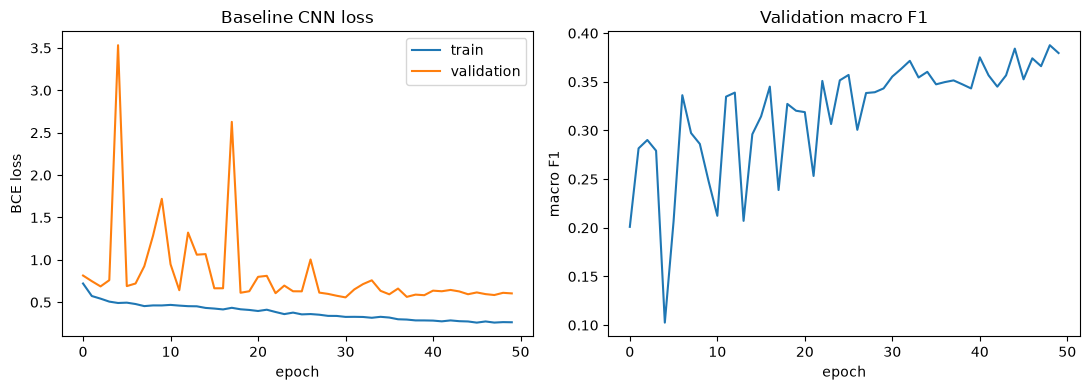

In [15]:
# 7. BASELINE CNN (50 epochs)
from porkinspect.baseline import train_baseline, predict_scores, TrayDataset
from torch.utils.data import DataLoader
t0 = time.perf_counter()
gc.collect(); torch.cuda.empty_cache()
cnn, hist = train_baseline(records["train"], records["valid"], N, epochs=CNN_EPOCHS, batch_size=32, num_workers=WORKERS)
train_min["cnn"] = (time.perf_counter() - t0) / 60
S["cnn"] = {s: predict_scores(cnn, DataLoader(TrayDataset(records[s], N), batch_size=64, num_workers=0), "cuda")[0] for s in ("valid", "test")}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation"); ax[0].legend()
ax[0].set(xlabel="epoch", ylabel="BCE loss", title="Baseline CNN loss")
ax[1].plot(hist["val_macro_f1"]); ax[1].set(xlabel="epoch", ylabel="macro F1", title="Validation macro F1")
plt.tight_layout(); plt.savefig(f"{OUT}/cnn_training_curves.png", dpi=150); plt.show(); plt.close("all")

In [16]:
# 8. VALIDATION: thresholds chosen on VALIDATION by cost; evaluated once on TEST
from porkinspect.metrics import (cost_threshold, multilabel_report, threshold_sweep, best_threshold,
                                 always_fail_predictions, bootstrap_ci, paired_bootstrap, tray_cost)
TH = np.round(np.arange(0.05, 0.96, 0.05), 2)
common = int(np.argmax(truth(records["train"]).sum(axis=0)))
P, results = {}, {"settings": {"GAP": GAP, "IMGSZ": IMGSZ, "MISS_COST": MISS_COST, "WASTE_COST": WASTE_COST,
                               "EPOCHS": EPOCHS, "CNN_EPOCHS": CNN_EPOCHS, "best_yolo": BEST, "split_seed": split["seed"]}}
for m in S:
    c = cost_threshold(Y["valid"], S[m]["valid"], TH, MISS_COST, WASTE_COST)
    f1_thr = best_threshold(threshold_sweep(Y["valid"], S[m]["valid"], TH), "macro_f1")
    P[m] = S[m]["test"] >= c["threshold"]
    results[m] = {"threshold_cost": c["threshold"], "threshold_f1": f1_thr, "val_costs": c["costs"].tolist(),
                  "test": multilabel_report(Y["test"], P[m], CLASS_NAMES),
                  "test_cost": tray_cost(Y["test"], P[m], MISS_COST, WASTE_COST),
                  "sweep_test": {k: v.tolist() for k, v in threshold_sweep(Y["test"], S[m]["test"], TH).items()}}
P["always_fail"] = always_fail_predictions(Y["test"], common)
results["always_fail"] = {"test": multilabel_report(Y["test"], P["always_fail"], CLASS_NAMES),
                          "test_cost": tray_cost(Y["test"], P["always_fail"], MISS_COST, WASTE_COST)}
bal = lambda t, p: multilabel_report(t, p, CLASS_NAMES)["tray"]["balanced_accuracy"]
main_names = [CLASS_NAMES[i] for i in main]
f1m = lambda t, p: multilabel_report(t[:, main], p[:, main], main_names)["macro_f1"]
results["bootstrap"] = {m: {"balanced_accuracy": bootstrap_ci(Y["test"], P[m], bal),
                            "macro_f1_main": bootstrap_ci(Y["test"], P[m], f1m)} for m in P}
results["paired"] = {f"{a}_minus_{b}": {"balanced_accuracy": paired_bootstrap(Y["test"], P[a], P[b], bal),
                                         "macro_f1_main": paired_bootstrap(Y["test"], P[a], P[b], f1m)}
                     for a, b in [(BEST, "cnn"), (BEST, "always_fail")] + [(k, BEST) for k in yolo if k != BEST]}
print(f"{'model':14s} thr  caught  good-rejected  bal.acc [95% CI]        macroF1-main [95% CI]   cost")
for m in P:
    t = results[m]["test"]["tray"]; b = results["bootstrap"][m]
    thr = results[m].get("threshold_cost", "-")
    print(f"{m:14s} {thr!s:4s} {t['tp']:3d}/{t['tp'] + t['fn']:<3d} {t['fp']:3d}/{t['n_pass_trays']:<3d}        "
          f"{b['balanced_accuracy']['estimate']:.2f} [{b['balanced_accuracy']['low']:.2f}, {b['balanced_accuracy']['high']:.2f}]   "
          f"{b['macro_f1_main']['estimate']:.2f} [{b['macro_f1_main']['low']:.2f}, {b['macro_f1_main']['high']:.2f}]   {results[m]['test_cost']:.0f}")
print(json.dumps(results["paired"], indent=1))

model          thr  caught  good-rejected  bal.acc [95% CI]        macroF1-main [95% CI]   cost
yolov8n        0.05 164/166  22/29         0.61 [0.54, 0.70]   0.83 [0.79, 0.87]   42
yolov8s        0.05 164/166  20/29         0.65 [0.56, 0.74]   0.88 [0.85, 0.91]   40
cnn            0.35 166/166  29/29         0.50 [0.50, 0.50]   0.87 [0.83, 0.90]   29
always_fail    -    166/166  29/29         0.50 [0.50, 0.50]   0.31 [0.27, 0.34]   29
{
 "yolov8n_minus_cnn": {
  "balanced_accuracy": {
   "diff": 0.11466555878687157,
   "low": 0.04125897129186609,
   "high": 0.2002759538584472,
   "p_a_not_better": 0.0015
  },
  "macro_f1_main": {
   "diff": -0.030688447170536093,
   "low": -0.06622804097567878,
   "high": 0.005721859084309047,
   "p_a_not_better": 0.956
  }
 },
 "yolov8n_minus_always_fail": {
  "balanced_accuracy": {
   "diff": 0.11466555878687157,
   "low": 0.04125897129186609,
   "high": 0.2002759538584472,
   "p_a_not_better": 0.0015
  },
  "macro_f1_main": {
   "diff": 0.526098205

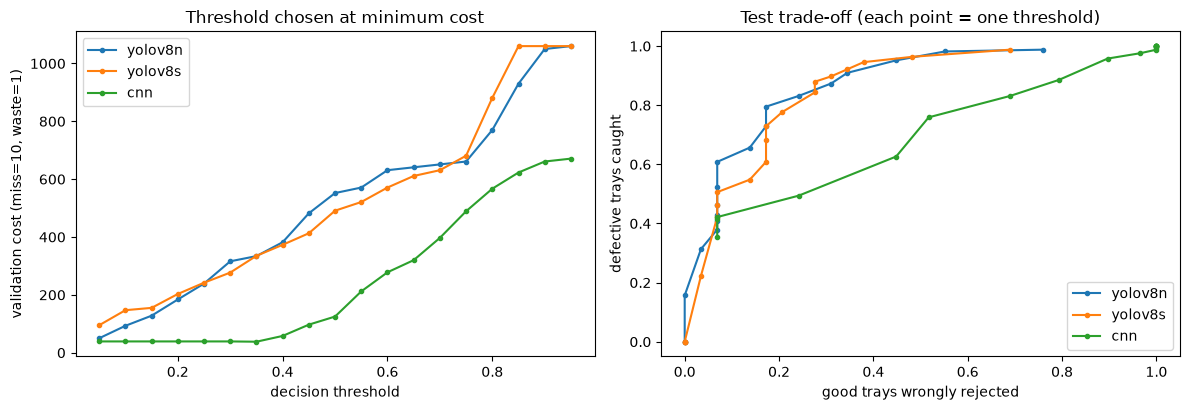

In [17]:
# 9. SENSITIVITY: cost on validation vs threshold, and the test trade-off curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for m in S:
    ax[0].plot(TH, results[m]["val_costs"], marker="o", ms=3, label=m)
    sw = results[m]["sweep_test"]
    ax[1].plot(sw["tray_false_fail_rate"], sw["tray_fail_recall"], marker="o", ms=3, label=m)
ax[0].set(xlabel="decision threshold", ylabel=f"validation cost (miss={MISS_COST}, waste={WASTE_COST})", title="Threshold chosen at minimum cost"); ax[0].legend()
ax[1].set(xlabel="good trays wrongly rejected", ylabel="defective trays caught", title="Test trade-off (each point = one threshold)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/threshold_cost.png", dpi=150); plt.show()

In [18]:
# 10. PERFORMANCE: latency GPU + CPU, GFLOPs, parameters
from porkinspect.performance import time_function, count_flops, required_throughput
from porkinspect.io_utils import load_image
from porkinspect.baseline import preprocess
img = load_image(records["test"][0].image_path)[0]; bgr = img[:, :, ::-1].copy()
perf = {}
for m, mod in yolo.items():
    perf[m] = {"gpu_ms": time_function(lambda: mod.predict(bgr, imgsz=IMGSZ, verbose=False), 10, 50)["median_ms"],
               "cpu_ms": time_function(lambda: mod.predict(bgr, imgsz=IMGSZ, device="cpu", verbose=False), 3, 20, sync_cuda=False)["median_ms"],
               "gflops": model_gflops(mod, IMGSZ), "params": float(sum(p.numel() for p in mod.model.parameters())),
               "train_min": train_min[m]}
x = preprocess(img).unsqueeze(0)
cnn.eval().cuda(); g = time_function(lambda: cnn(x.cuda()), 10, 50)["median_ms"]
cnn_cpu = cnn.cpu(); c = time_function(lambda: cnn_cpu(x), 3, 20, sync_cuda=False)["median_ms"]; cnn.cuda()
fl = count_flops(cnn, tuple(x.shape))
perf["cnn"] = {"gpu_ms": g, "cpu_ms": c, "gflops": fl["flops"] / 1e9, "params": fl["params"],
               "arithmetic_intensity": fl["arithmetic_intensity"], "train_min": train_min["cnn"]}
perf["line_budget"] = required_throughput(60)
results["performance"], results["box_metrics"] = perf, box
print(json.dumps(perf, indent=1, default=float))

{
 "yolov8n": {
  "gpu_ms": 15.049349996843375,
  "cpu_ms": 50.56539999350207,
  "gflops": 8.7542912,
  "params": 3138975.0,
  "train_min": 14.70406702166656
 },
 "yolov8s": {
  "gpu_ms": 14.476950003881939,
  "cpu_ms": 122.19249999907333,
  "gflops": 28.6506496,
  "params": 11137535.0,
  "train_min": 29.206336736666707
 },
 "cnn": {
  "gpu_ms": 2.336799996555783,
  "cpu_ms": 24.013850001210812,
  "gflops": 2.07913216,
  "params": 537893.0,
  "arithmetic_intensity": 81.06242337768103,
  "train_min": 24.8171476233331
 },
 "line_budget": {
  "budget_ms": 1000.0,
  "required_fps": 1.0
 }
}


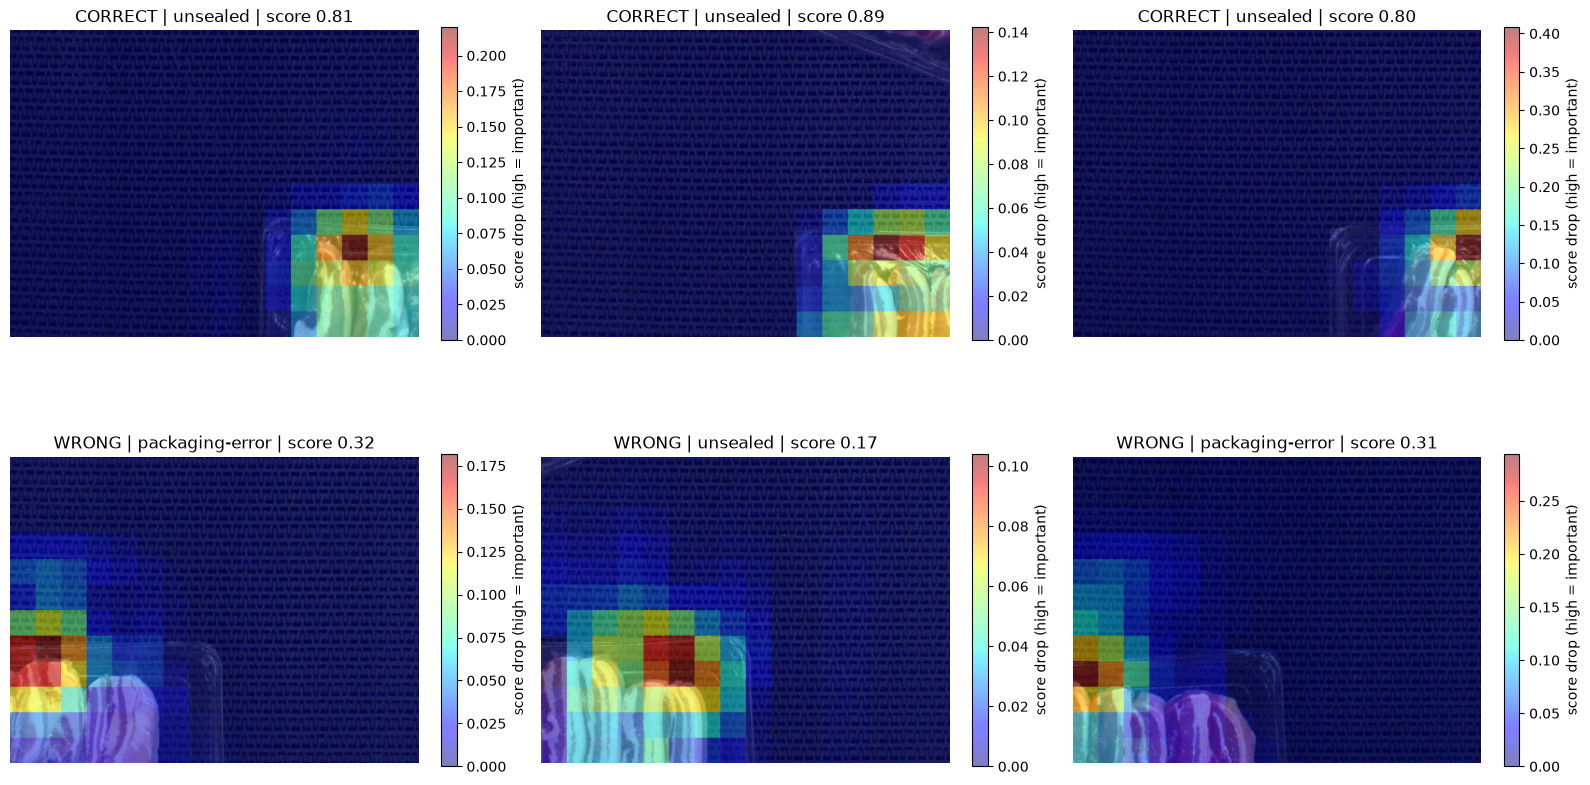

In [19]:
# 11. ERROR INVESTIGATION: occlusion maps for the chosen YOLO (colour scale fixed at 0)
from porkinspect.occlusion import occlusion_map, overlay
mdl, thr = yolo[BEST], results[BEST]["threshold_cost"]
pred = S[BEST]["test"] >= thr
correct = [i for i in range(len(pred)) if (pred[i] == Y["test"][i].astype(bool)).all() and Y["test"][i].any()]
wrong = [i for i in range(len(pred)) if not (pred[i] == Y["test"][i].astype(bool)).all()]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (i, ok) in zip(axes.ravel(), [(i, True) for i in correct[:3]] + [(i, False) for i in wrong[:3]]):
    im = load_image(records["test"][i].image_path)[0]
    tc = np.flatnonzero(Y["test"][i]); c = int(tc[np.argmax(S[BEST]["test"][i][tc])]) if len(tc) else int(np.argmax(S[BEST]["test"][i]))
    def score(a, c=c):
        r = mdl.predict(a[:, :, ::-1].copy(), conf=0.01, imgsz=IMGSZ, verbose=False)[0]
        cf = r.boxes.conf.cpu().numpy()[r.boxes.cls.cpu().numpy() == c]
        return float(cf.max()) if len(cf) else 0.0
    heat, base = occlusion_map(score, im, patch=90, stride=45)
    overlay(im, heat, ax=ax, title=f"{'CORRECT' if ok else 'WRONG'} | {CLASS_NAMES[c]} | score {base:.2f}")
plt.tight_layout(); plt.savefig(f"{OUT}/occlusion_maps.png", dpi=130); plt.show()

In [20]:
# 12. SAVE AND DOWNLOAD
Path(f"{OUT}/results.json").write_text(json.dumps(results, indent=1, default=float))
np.savez(f"{OUT}/scores.npz", Y_valid=Y["valid"], Y_test=Y["test"],
         **{f"{m}_{s}": S[m][s] for m in S for s in ("valid", "test")},
         test_files=np.array([r.image_path.name for r in records["test"]]))
shutil.copy(run_dir(f"run2_{BEST}") / "weights" / "best.pt", f"{OUT}/{BEST}_best.pt")
shutil.make_archive("results_run2", "zip", root_dir=".", base_dir=OUT)
try:                                   # Google Colab: download straight away
    from google.colab import files
    files.download("results_run2.zip")
except ImportError:                    # Kaggle / local: the file is in the working folder
    print("Download results_run2.zip from the Output panel (Kaggle) or the file browser:", os.path.abspath("results_run2.zip"))

Download results_run2.zip from the Output panel (Kaggle) or the file browser: c:\Users\truon\Documents\DU HỌC\Sem 2 - 2026\MMA3001\Project\pork-rasher-inspection\results_run2.zip
